# Group size, budget and noise level on the toy problem

The official config samples 48 groups of 24 images per epoch. On one GPU I will have far fewer. Three questions before spending GPU money, answered on the toy problem only:

1. with a fixed number of samples per iteration, does it matter how they are split into groups?
2. how low can the number of samples per iteration go?
3. does the noise level matter?

5 seeds each, 100 iterations, no KL.

Same code as in notebook 05.

In [1]:
import math

import matplotlib.pyplot as plt
import torch
import torch.nn as nn

torch.manual_seed(0)
torch.set_num_threads(4)

SURFACE, INK, GRID, MUTED = "#fcfcfb", "#52514e", "#e1e0d9", "#c3c2b7"
COLORS = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100"]


def style(ax, grid="y"):
    ax.set_facecolor(SURFACE)
    ax.grid(axis=grid, color=GRID, lw=1)
    ax.set_axisbelow(True)
    ax.tick_params(length=0, colors=INK)
    for side in ("top", "right", "left"):
        ax.spines[side].set_visible(False)
    ax.spines["bottom"].set_color(MUTED)


K = 8
RADIUS = 2.0
HALF_ARC = math.pi / K * 0.7
R_STD = 0.08


def sample_data(c):
    center = 2 * math.pi * c / K
    angle = center + (torch.rand(len(c)) * 2 - 1) * HALF_ARC
    radius = RADIUS + R_STD * torch.randn(len(c))
    return torch.stack([radius * torch.cos(angle), radius * torch.sin(angle)], dim=1)


class Velocity(nn.Module):
    def __init__(self, hidden=128):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(2 + 1 + K, hidden),
            nn.SiLU(),
            nn.Linear(hidden, hidden),
            nn.SiLU(),
            nn.Linear(hidden, hidden),
            nn.SiLU(),
            nn.Linear(hidden, 2),
        )

    def forward(self, x, t, c):
        onehot = nn.functional.one_hot(c, K).float()
        return self.net(torch.cat([x, t[:, None], onehot], dim=1))


def train_flow(steps=4000, batch=512, lr=2e-3):
    model = Velocity()
    opt = torch.optim.Adam(model.parameters(), lr=lr)
    sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, steps)
    losses = []
    for _ in range(steps):
        c = torch.randint(K, (batch,))
        x0 = sample_data(c)
        noise = torch.randn_like(x0)
        t = torch.rand(batch)
        xt = (1 - t)[:, None] * x0 + t[:, None] * noise
        loss = ((model(xt, t, c) - (noise - x0)) ** 2).mean()
        opt.zero_grad()
        loss.backward()
        opt.step()
        sched.step()
        losses.append(loss.item())
    return model, losses


@torch.no_grad()
def sample_ode(model, c, steps=40, noise=None):
    x = torch.randn(len(c), 2) if noise is None else noise.clone()
    ts = torch.linspace(1, 0, steps + 1)
    for t, t_next in zip(ts[:-1], ts[1:]):
        x = x + model(x, t.expand(len(c)), c) * (t_next - t)
    return x


def describe(x, c):
    radius = x.norm(dim=1)
    angle = torch.atan2(x[:, 1], x[:, 0])
    offset = (angle - 2 * math.pi * c / K + math.pi) % (2 * math.pi) - math.pi
    inside = (offset.abs() <= HALF_ARC) & ((radius - RADIUS).abs() <= 3 * R_STD)
    return {
        "inside": inside.float().mean().item(),
        "radius std": radius.std().item(),
        "angle std": offset.std().item(),
    }


def sde_step(v, x, t, t_next, noise_level, t_second, x_next=None):
    dt = t_next - t  # negative, time goes from 1 to 0
    t_safe = t_second if float(t) == 1.0 else t
    std = noise_level * torch.sqrt(t / (1 - t_safe))
    mean = x * (1 + std**2 / (2 * t) * dt) + v * (1 + std**2 * (1 - t) / (2 * t)) * dt
    step_std = std * torch.sqrt(-dt)
    if x_next is None:
        x_next = mean + step_std * torch.randn_like(x)
    log_prob = (
        -((x_next.detach() - mean) ** 2) / (2 * step_std**2)
        - torch.log(step_std)
        - 0.5 * math.log(2 * math.pi)
    ).mean(dim=1)
    return x_next, log_prob, mean, std


GOAL_STD = 0.3


def reward_fn(x, c):
    center = 2 * math.pi * c / K
    goal = torch.stack([RADIUS * torch.cos(center), RADIUS * torch.sin(center)], dim=1)
    return torch.exp(-((x - goal) ** 2).sum(dim=1) / (2 * GOAL_STD**2))


def grpo(base, iters=150, n_groups=8, group_size=24, steps=10, noise_level=0.7,
         lr=3e-4, clip=0.1, beta=0.0, seed=0, eval_every=10):
    torch.manual_seed(seed)
    model = Velocity()
    model.load_state_dict(base.state_dict())
    opt = torch.optim.Adam(model.parameters(), lr=lr)
    ts = torch.linspace(1, 0, steps + 1)
    eval_c = torch.arange(K).repeat_interleave(256)
    eval_noise = torch.randn(len(eval_c), 2, generator=torch.Generator().manual_seed(123))
    history = []
    first_ratio = None

    for it in range(iters + 1):
        if it % eval_every == 0:
            x_eval = sample_ode(model, eval_c, 40, eval_noise)
            history.append({"iter": it, "reward": reward_fn(x_eval, eval_c).mean().item(),
                            **describe(x_eval, eval_c)})
        if it == iters:
            break

        # sample groups with the current model
        c = torch.randint(K, (n_groups,)).repeat_interleave(group_size)
        group = torch.arange(n_groups).repeat_interleave(group_size)
        x = torch.randn(len(c), 2)
        traj = []
        with torch.no_grad():
            for i in range(steps):
                v = model(x, ts[i].expand(len(c)), c)
                x_next, logp, _, _ = sde_step(v, x, ts[i], ts[i + 1], noise_level, ts[1])
                traj.append((x, x_next, logp))
                x = x_next

        # advantage: minus the group mean, divided by the std of all rewards
        rewards = reward_fn(x, c)
        group_mean = torch.zeros(n_groups).index_add_(0, group, rewards) / group_size
        adv = ((rewards - group_mean[group]) / (rewards.std() + 1e-4)).clamp(-5, 5)

        for j in torch.randperm(steps).tolist():
            x_j, x_next_j, old_logp = traj[j]
            t = ts[j].expand(len(c))
            _, logp, mean, std = sde_step(model(x_j, t, c), x_j, ts[j], ts[j + 1],
                                          noise_level, ts[1], x_next=x_next_j)
            ratio = torch.exp(logp - old_logp)
            if first_ratio is None:
                first_ratio = (ratio - 1).abs().max().item()
            loss = torch.maximum(-adv * ratio, -adv * ratio.clamp(1 - clip, 1 + clip)).mean()
            if beta > 0:
                with torch.no_grad():
                    _, _, mean_ref, _ = sde_step(base(x_j, t, c), x_j, ts[j], ts[j + 1],
                                                 noise_level, ts[1], x_next=x_next_j)
                loss = loss + beta * (((mean - mean_ref) ** 2).mean(dim=1) / (2 * std**2)).mean()
            opt.zero_grad()
            loss.backward()
            opt.step()

    return model, history, first_ratio


base, _ = train_flow()

In [2]:
def run_many(**kwargs):
    return [grpo(base, iters=100, seed=seed, **kwargs)[1] for seed in range(5)]


def reward_at(histories, it):
    values = torch.tensor([h["reward"] for hist in histories for h in hist if h["iter"] == it])
    return values.mean().item(), values.std(unbiased=False).item()


def table(results, header):
    print(f"{header:<22}" + "".join(f"{f'iter {it}':>16}" for it in (10, 20, 50, 100)) + f"{'worst after 50':>16}")
    for name, histories in results.items():
        cells = "".join("{:>10.3f} ±{:.3f}".format(*reward_at(histories, it)) for it in (10, 20, 50, 100))
        worst = min(h["reward"] for hist in histories for h in hist if h["iter"] >= 50)
        print(f"{name:<22}{cells}{worst:>16.3f}")

## 1. Group size at a fixed budget

96 samples per iteration, split four ways.

In [3]:
by_group = {
    f"{96 // g} groups of {g}": run_many(n_groups=96 // g, group_size=g) for g in (4, 8, 12, 24)
}
table(by_group, "96 samples")

96 samples                     iter 10         iter 20         iter 50        iter 100  worst after 50
24 groups of 4             0.895 ±0.008     0.953 ±0.009     0.978 ±0.010     0.979 ±0.010           0.950
12 groups of 8             0.902 ±0.006     0.952 ±0.005     0.976 ±0.007     0.980 ±0.012           0.912
8 groups of 12             0.906 ±0.013     0.953 ±0.009     0.979 ±0.009     0.986 ±0.004           0.940
4 groups of 24             0.884 ±0.015     0.942 ±0.014     0.965 ±0.014     0.976 ±0.010           0.943


No real difference. All four end at 0.98 and the gaps are within the seed noise (about ±0.01). 4 groups of 24 is a little behind at the start, 0.884 at iteration 10 against 0.90 for the others. With 4 groups an iteration sees at most 4 of the 8 classes, that may be why.

## 2. Samples per iteration

Groups of 24, from 1 group to 8 groups per iteration.

In [4]:
by_budget = {f"{n * 24} samples": run_many(n_groups=n, group_size=24, eval_every=5) for n in (1, 2, 4, 8)}
table(by_budget, "groups of 24")

groups of 24                   iter 10         iter 20         iter 50        iter 100  worst after 50
24 samples                 0.808 ±0.021     0.825 ±0.027     0.900 ±0.016     0.907 ±0.021           0.762
48 samples                 0.856 ±0.015     0.913 ±0.015     0.932 ±0.012     0.965 ±0.015           0.856
96 samples                 0.884 ±0.015     0.942 ±0.014     0.965 ±0.014     0.976 ±0.010           0.919
192 samples                0.937 ±0.010     0.965 ±0.021     0.984 ±0.002     0.974 ±0.008           0.960


Per iteration more samples is obviously better. The fair comparison is by total samples drawn, since that is what costs GPU time.

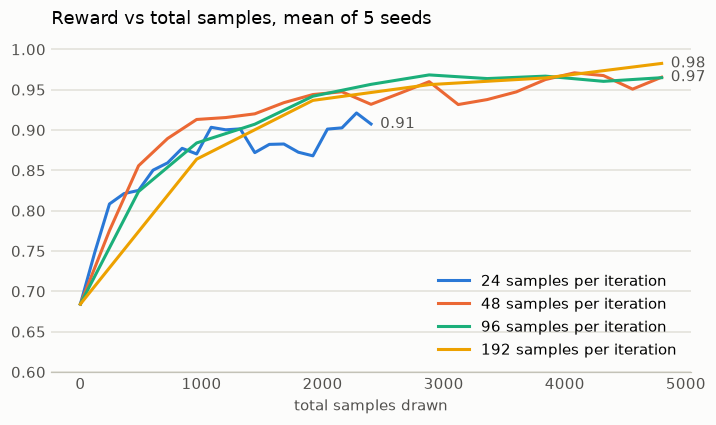

                reward after ~2400 samples
24 samples                   0.907  (iter 100)
48 samples                   0.932  (iter 50)
96 samples                   0.957  (iter 25)
192 samples                  0.937  (iter 10)


In [5]:
fig, ax = plt.subplots(figsize=(7.5, 4), dpi=110, facecolor=SURFACE)
placed = []
for (name, histories), color in zip(by_budget.items(), COLORS):
    per_iter = int(name.split()[0])
    iters = [h["iter"] for h in histories[0]]
    xs = [it * per_iter for it in iters]
    ys = [reward_at(histories, it)[0] for it in iters]
    keep = [i for i, x in enumerate(xs) if x <= 4800]
    ax.plot([xs[i] for i in keep], [ys[i] for i in keep], color=color, lw=2, label=f"{name} per iteration")
    last = keep[-1]
    if all(abs(ys[last] - y) > 0.012 for y in placed):
        ax.annotate(f"{ys[last]:.2f}", (xs[last], ys[last]), xytext=(6, 0),
                    textcoords="offset points", va="center", color=INK)
        placed.append(ys[last])
style(ax)
ax.set_ylim(0.6, 1.02)
ax.set_xlabel("total samples drawn", color=INK)
ax.set_title("Reward vs total samples, mean of 5 seeds", loc="left")
ax.legend(frameon=False, loc="lower right")
plt.show()

print(f"{'':<14}{'reward after ~2400 samples':>28}")
for name, histories in by_budget.items():
    per_iter = int(name.split()[0])
    it = min((h["iter"] for h in histories[0]), key=lambda i: abs(i * per_iter - 2400))
    print(f"{name:<14}{reward_at(histories, it)[0]:>20.3f}  (iter {it})")

For the same ~2400 samples: 0.907 with 24 per iteration, 0.932 with 48, 0.957 with 96, 0.937 with 192.

24 per iteration is bad twice: it learns less per sample and it is unstable, the worst evaluation after iteration 50 was 0.76. 192 is not better than 96 per sample drawn, it only needs fewer updates.

## 3. Noise level

4 groups of 24.

In [6]:
by_noise = {f"a={a}": run_many(n_groups=4, group_size=24, noise_level=a) for a in (0.3, 0.7, 1.0)}
table(by_noise, "noise level")

noise level                    iter 10         iter 20         iter 50        iter 100  worst after 50
a=0.3                      0.874 ±0.011     0.950 ±0.005     0.977 ±0.010     0.983 ±0.009           0.947
a=0.7                      0.884 ±0.015     0.942 ±0.014     0.965 ±0.014     0.976 ±0.010           0.943
a=1.0                      0.857 ±0.014     0.918 ±0.021     0.952 ±0.016     0.952 ±0.012           0.921


0.3 and 0.7 end about the same, 0.983 and 0.976. 1.0 is behind the whole way and ends at 0.952. Notebook 04 showed that at 10 steps a=1.0 distorts the samples the most, so this fits.

## Notes for later

- this is a 2D toy with 8 classes and a smooth reward. It says what to try first on SD3, not what will happen there
- group size did not matter here. On SD3 it is worth trying groups smaller than 24 early, that leaves room for more prompts per iteration with the same number of images
- 24 samples per iteration was too few, 48 worked but slower. Compare configs by reward per total samples, not per iteration
- noise 0.7 as in the official config is fine, 1.0 is worse